# HW1: Boston NDVI and Vegetation Cover

Calculates NDVI from Boston NAIP images and summarizes vegetation cover for each census tract.

## 1. Import libraries and set file paths

In [12]:
# Import the libraries needed for this homework
from pathlib import Path
import fiona
from rasterio.mask import mask

import numpy as np
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
from matplotlib import pyplot as plt

import os
import urllib.request
import fiona
import pystac_client
import planetary_computer as pc

from shapely.geometry import shape, box, mapping

# Import data paths
data_folder = Path("data")
naip_folder = data_folder / "allentown_naip"
output_folder = Path("outputs")

output_folder.mkdir(exist_ok=True)

print("Using data from:", data_folder)

Using data from: data


In [13]:
# Read Allentown's city boundary and census tracts
city_file = data_folder / "Allentown_CityLimit.shp"
tract_file = data_folder / "Allentown_census_tracts.shp"

allentown = gpd.read_file(city_file).to_crs("EPSG:4326")

# Save an EPSG:4326 version for the NAIP downloader
allentown.to_file(
    data_folder / "allentown_city_limit_4326.geojson",
    driver="GeoJSON"
)

city_geom = allentown.geometry.union_all()

tracts_all = gpd.read_file(tract_file).to_crs("EPSG:4326")

# Keep tracts that overlap Allentown
tracts = tracts_all[tracts_all.intersects(city_geom)].copy()
tracts["tract_id"] = np.arange(1, len(tracts) + 1)

print("Number of census tracts:", len(tracts))

Number of census tracts: 28


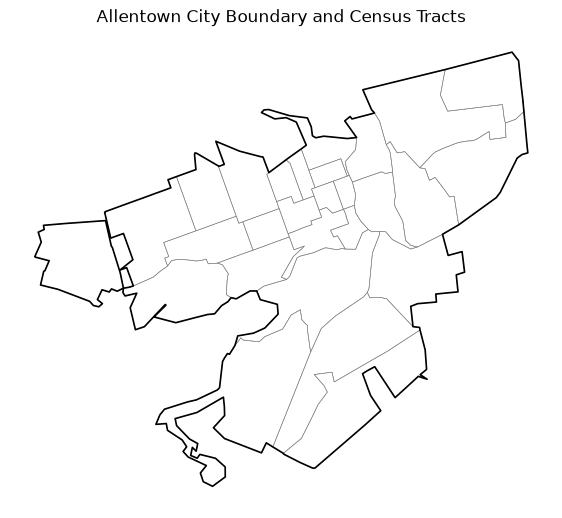

In [15]:
# Make a quick map to check the Allentown boundary and census tracts
fig, ax = plt.subplots(figsize=(7, 7))

tracts.boundary.plot(ax=ax, color="gray", linewidth=0.4)
allentown.boundary.plot(ax=ax, color="black", linewidth=1.2)

ax.set_title("Allentown City Boundary and Census Tracts")
ax.set_axis_off()
plt.show()

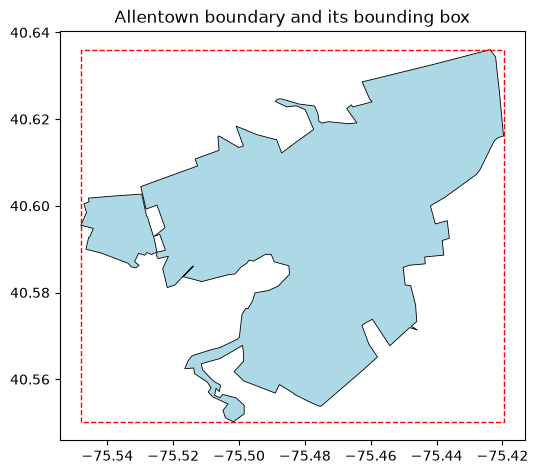

In [17]:
from shapely.geometry import box

left, bottom, right, top = allentown.total_bounds

fig, ax = plt.subplots(figsize=(6, 6))

allentown.plot(
    ax=ax,
    color="lightblue",
    edgecolor="black",
    linewidth=0.6
)

gpd.GeoSeries(
    [box(left, bottom, right, top)],
    crs=allentown.crs
).boundary.plot(
    ax=ax,
    color="red",
    linestyle="--",
    linewidth=1
)

ax.set_title("Allentown boundary and its bounding box")
plt.show()

In [20]:
# NAIP download function
def naip_downloader(shpfile, outfolder, startDate, endDate,
                    skip_existing=True, max_tiles=None):
    """
    Download every NAIP tile that overlaps a study area, for a given date range.

    Tiles are saved unmodified, in NAIP's native band order:
        band 1 = Red, band 2 = Green, band 3 = Blue, band 4 = Near-Infrared

    Parameters
    ----------
    shpfile : str
        Path to a polygon shapefile of the study area. Must be in EPSG:4326.
    outfolder : str
        Folder to write the GeoTIFFs into. Created if it does not exist.
    startDate, endDate : str
        Date range to search, as 'YYYY-MM-DD' (e.g. '2017-06-01', '2017-09-30').
    skip_existing : bool
        If True, do not re-download tiles that are already in `outfolder`.
    max_tiles : int or None
        Stop after this many tiles. Useful for testing; None means download all.

    Returns
    -------
    list of str
        Paths of the tiles that now exist locally for this study area.
    """
    os.makedirs(outfolder, exist_ok=True)

    # --- 1. Read the study area, and build a bounding box for the search ---
    with fiona.open(shpfile) as lyr:
        if lyr.crs.to_string() != 'EPSG:4326':
            raise ValueError(
                f"{shpfile} is in {lyr.crs.to_string()}; STAC needs EPSG:4326. "
                "Reproject it first: gpd.read_file(f).to_crs('EPSG:4326')"
            )
        city_parts = [shape(feat['geometry']) for feat in lyr]
        left, bottom, right, top = lyr.bounds

    area_of_interest = mapping(box(left, bottom, right, top))

    # --- 2. Search the catalog -------------------------------------------
    catalog = pystac_client.Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1",
        modifier=pc.sign_inplace,      # sign every asset URL for us
    )
    items_tiles = catalog.search(
        collections=["naip"],
        intersects=area_of_interest,
        datetime=f"{startDate}/{endDate}",
    ).item_collection()

    print(f"{len(items_tiles)} tiles found for {startDate}/{endDate}")

    # --- 3. Keep only the tiles that really touch the study area ----------
    # item.geometry is the tile footprint in EPSG:4326, the same CRS as the study
    # area, so we can compare them directly -- and we do it BEFORE downloading.
    keep = [it for it in items_tiles
            if any(shape(it.geometry).intersects(part) for part in city_parts)]
    print(f"{len(keep)} of them actually intersect the study area "
          f"({len(items_tiles) - len(keep)} bounding-box-only tiles skipped)")

    if max_tiles:
        keep = keep[:max_tiles]

    # --- 4. Download ------------------------------------------------------
    downloaded = []
    for n, item in enumerate(keep, start=1):
        outfilename = os.path.join(outfolder, item.id + ".tif")

        if skip_existing and os.path.exists(outfilename):
            print(f"[{n}/{len(keep)}] {item.id} -- already on disk")
            downloaded.append(outfilename)
            continue

        print(f"[{n}/{len(keep)}] downloading {item.id} ...")
        urllib.request.urlretrieve(item.assets["image"].href, outfilename)
        downloaded.append(outfilename)

    print(f"\n{len(downloaded)} tiles available in '{outfolder}'")
    return downloaded

In [21]:
# Download Allentown NAIP imagery

allentown_boundary_4326 = data_folder / "allentown_city_limit_4326.geojson"
allentown_naip_folder = data_folder / "allentown_naip"

downloaded_tiles = naip_downloader(
    shpfile=str(allentown_boundary_4326),
    outfolder=str(allentown_naip_folder),
    startDate="2019-01-01",
    endDate="2020-12-31",
    skip_existing=True,
    max_tiles=None
)

print("Tiles available:", len(downloaded_tiles))

9 tiles found for 2019-01-01/2020-12-31
7 of them actually intersect the study area (2 bounding-box-only tiles skipped)
[1/7] downloading pa_m_4007529_sw_18_060_20191019_20191203 ...
[2/7] downloading pa_m_4007529_nw_18_060_20191019_20191203 ...
[3/7] downloading pa_m_4007529_ne_18_060_20191019_20191203 ...
[4/7] downloading pa_m_4007528_se_18_060_20191019_20191203 ...
[5/7] downloading pa_m_4007528_ne_18_060_20191019_20191203 ...
[6/7] downloading pa_m_4007521_sw_18_060_20191019_20191203 ...
[7/7] downloading pa_m_4007521_se_18_060_20191019_20191203 ...

7 tiles available in 'data\allentown_naip'
Tiles available: 7


Number of NAIP tiles: 7
Example tile: pa_m_4007521_se_18_060_20191019_20191203.tif
CRS: EPSG:26918
Bands: 4


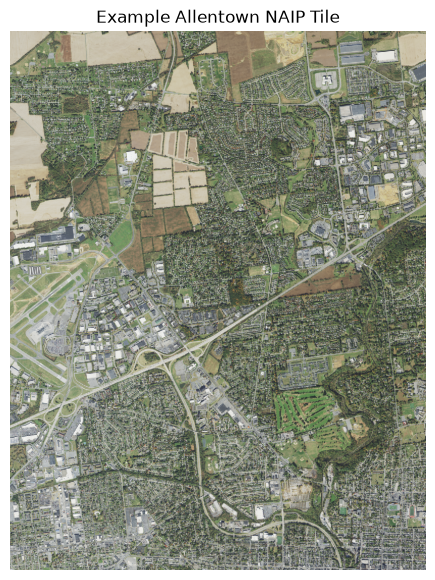

In [22]:
## Open and inspect the Allentown NAIP image tiles

tile_paths = sorted(allentown_naip_folder.glob("*.tif"))

print("Number of NAIP tiles:", len(tile_paths))

with rasterio.open(tile_paths[0]) as src:
    print("Example tile:", tile_paths[0].name)
    print("CRS:", src.crs)
    print("Bands:", src.count)

    height = src.height // 12
    width = src.width // 12

    # NAIP: 1=Red, 2=Green, 3=Blue, 4=Near-Infrared
    rgb = src.read([1, 2, 3], out_shape=(3, height, width))

rgb = np.moveaxis(rgb, 0, -1)

plt.figure(figsize=(7, 7))
plt.imshow(rgb)
plt.title("Example Allentown NAIP Tile")
plt.axis("off")
plt.show()

In [35]:
## Mosaic the Allentown NAIP tiles

from contextlib import ExitStack
from rasterio.merge import merge

mosaic_file = data_folder / "allentown_naip_mosaic.tif"

if not tile_paths:
    raise FileNotFoundError("No NAIP tiles found. Run the download cell first.")

if mosaic_file.exists():
    print("Using existing mosaic:", mosaic_file)

else:
    with ExitStack() as stack:
        src_files = [
            stack.enter_context(rasterio.open(tile_path))
            for tile_path in tile_paths
        ]

        mosaic_meta = src_files[0].meta.copy()
        mosaic_meta.update(
            driver="GTiff",
            compress="lzw",
            BIGTIFF="YES"
        )

        # Write in chunks to avoid a memory error
        merge(
            src_files,
            dst_path=str(mosaic_file),
            dst_kwds=mosaic_meta,
            method="first",
            mem_limit=256
        )

    print("Mosaic saved to:", mosaic_file)

Using existing mosaic: data\allentown_naip_mosaic.tif


In [36]:
## Reproject the Allentown boundary to the NAIP mosaic CRS

with rasterio.open(mosaic_file) as src:
    allentown_projected = allentown.to_crs(src.crs)

projected_boundary_file = data_folder / "allentown_city_limit_projected.shp"
allentown_projected.to_file(projected_boundary_file)

print("NAIP mosaic CRS:", allentown_projected.crs)

NAIP mosaic CRS: PROJCS["NAD83 / UTM zone 18N",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-75],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","26918"]]


In [37]:
## Mask the mosaicked Allentown raster to the city boundary

import fiona
from rasterio.mask import mask

input_value_raster = mosaic_file
out_raster = data_folder / "allentown_naip_clipped.tif"

with fiona.open(projected_boundary_file, "r") as shapefile:
    shapes = [feature["geometry"] for feature in shapefile]

with rasterio.open(input_value_raster) as src:
    out_image, out_transform = mask(src, shapes, crop=True, nodata=0)
    out_meta = src.meta.copy()

out_meta.update({
    "driver": "GTiff",
    "height": out_image.shape[1],
    "width": out_image.shape[2],
    "compress": "lzw",
    "transform": out_transform,
    "nodata": 0,
    "BIGTIFF": "YES"
})

with rasterio.open(out_raster, "w", **out_meta) as dest:
    dest.write(out_image)

print("Clipped Allentown raster saved to:", out_raster)

Clipped Allentown raster saved to: data\allentown_naip_clipped.tif


In [38]:
## Clip the masked Allentown raster into smaller NAIP tiles

from rasterio.windows import Window

input_raster = data_folder / "allentown_naip_clipped.tif"
tile_folder = data_folder / "allentown_naip_tiles"
tile_folder.mkdir(exist_ok=True)

tile_width = 2000
tile_height = 2000

with rasterio.open(input_raster) as src:
    for row_off in range(0, src.height, tile_height):
        for col_off in range(0, src.width, tile_width):
            width = min(tile_width, src.width - col_off)
            height = min(tile_height, src.height - row_off)
            window = Window(col_off, row_off, width, height)

            tile_meta = src.meta.copy()
            tile_meta.update({
                "height": height,
                "width": width,
                "transform": rasterio.windows.transform(window, src.transform),
                "compress": "lzw"
            })

            tile_path = tile_folder / f"row_{row_off}_col_{col_off}.tif"
            with rasterio.open(tile_path, "w", **tile_meta) as dst:
                dst.write(src.read(window=window))

print("Small Allentown NAIP tiles saved to:", tile_folder)

Small Allentown NAIP tiles saved to: data\allentown_naip_tiles


In [39]:
## Calculate NDVI and vegetation-cover tiles for Allentown

input_folder = data_folder / "allentown_naip_tiles"
ndvi_folder = data_folder / "allentown_ndvi_tiles"
vegetation_folder = data_folder / "allentown_vegetation_tiles"
ndvi_folder.mkdir(exist_ok=True)
vegetation_folder.mkdir(exist_ok=True)

for tile_path in sorted(input_folder.glob("*.tif")):
    with rasterio.open(tile_path) as src:
        # NAIP band order: 1=Red, 2=Green, 3=Blue, 4=NIR
        red = src.read(1).astype("float32")
        nir = src.read(4).astype("float32")
        valid_pixels = (red != 0) | (nir != 0)
        denominator = nir + red

        ndvi = np.full(red.shape, -9999.0, dtype="float32")
        np.divide(nir - red, denominator, out=ndvi,
                  where=valid_pixels & (denominator != 0))
        vegetation = (valid_pixels & (ndvi > 0)).astype("uint8")

        ndvi_meta = src.meta.copy()
        ndvi_meta.update(count=1, dtype="float32", nodata=-9999.0, compress="lzw")
        vegetation_meta = src.meta.copy()
        vegetation_meta.update(count=1, dtype="uint8", nodata=0, compress="lzw")

        with rasterio.open(ndvi_folder / tile_path.name, "w", **ndvi_meta) as dst:
            dst.write(ndvi, 1)
        with rasterio.open(vegetation_folder / tile_path.name, "w", **vegetation_meta) as dst:
            dst.write(vegetation, 1)

print("NDVI tiles saved to:", ndvi_folder)
print("Vegetation tiles saved to:", vegetation_folder)

C:\Users\ccziy\AppData\Local\Temp\ipykernel_37840\3529015599.py:12: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  red = src.read(1).astype("float32")
C:\Users\ccziy\AppData\Local\Temp\ipykernel_37840\3529015599.py:13: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  nir = src.read(4).astype("float32")


NDVI tiles saved to: data\allentown_ndvi_tiles
Vegetation tiles saved to: data\allentown_vegetation_tiles


In [44]:
## Create citywide NDVI and vegetation-cover raster maps

from contextlib import ExitStack
from rasterio.merge import merge

allentown_ndvi_map = data_folder / "allentown_ndvi.tif"
allentown_greencover_map = data_folder / "allentown_greencover.tif"

def mosaic_tiles(tile_folder, output_file):
    tile_files = sorted(tile_folder.glob("*.tif"))

    if not tile_files:
        raise FileNotFoundError(f"No tiles found in {tile_folder}")

    with ExitStack() as stack:
        sources = [
            stack.enter_context(rasterio.open(tile_file))
            for tile_file in tile_files
        ]

        metadata = sources[0].meta.copy()
        metadata.update(driver="GTiff", compress="lzw", BIGTIFF="YES")

        merge(
            sources,
            dst_path=str(output_file),
            dst_kwds=metadata,
            method="first",
            mem_limit=256
        )

mosaic_tiles(ndvi_folder, allentown_ndvi_map)
mosaic_tiles(vegetation_folder, allentown_greencover_map)

print("NDVI map:", allentown_ndvi_map)
print("Vegetation map:", allentown_greencover_map)

NDVI map: data\allentown_ndvi.tif
Vegetation map: data\allentown_greencover.tif


C:\Users\ccziy\AppData\Local\Temp\ipykernel_37840\755684776.py:40: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  vegetation = src.read(


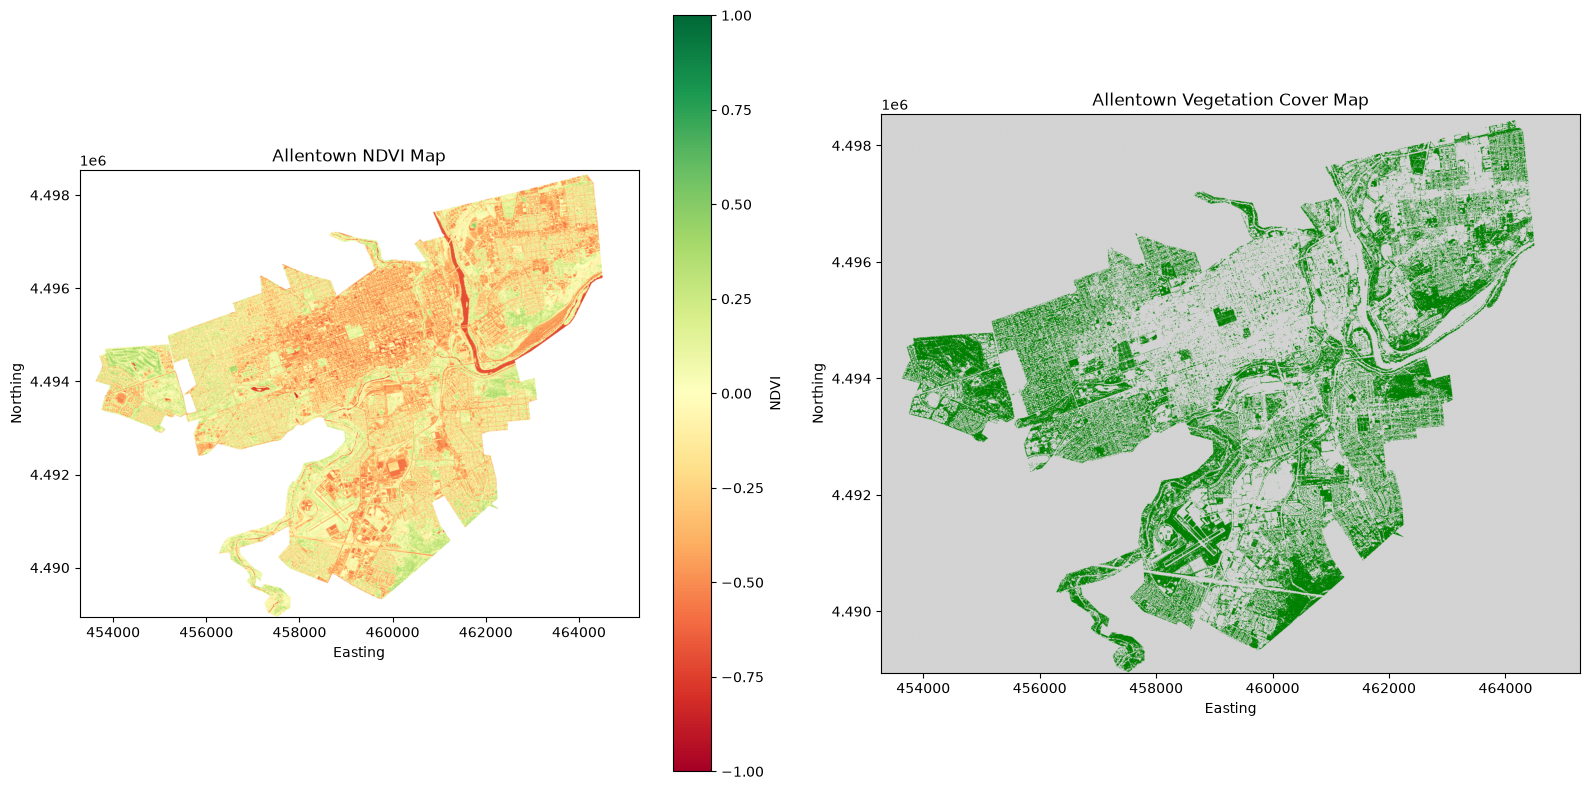

In [45]:
## Visualize Allentown NDVI and vegetation-cover maps

from matplotlib.colors import ListedColormap
from rasterio.enums import Resampling

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

with rasterio.open(allentown_ndvi_map) as src:
    height = max(1, src.height // 8)
    width = max(1, src.width // 8)

    ndvi = src.read(
        1,
        out_shape=(height, width),
        masked=True,
        resampling=Resampling.bilinear
    )

    extent = [
        src.bounds.left, src.bounds.right,
        src.bounds.bottom, src.bounds.top
    ]

ndvi_plot = axes[0].imshow(
    ndvi,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    extent=extent
)
axes[0].set_title("Allentown NDVI Map")
axes[0].set_xlabel("Easting")
axes[0].set_ylabel("Northing")
plt.colorbar(ndvi_plot, ax=axes[0], label="NDVI")

with rasterio.open(allentown_greencover_map) as src:
    height = max(1, src.height // 8)
    width = max(1, src.width // 8)

    vegetation = src.read(
        1,
        out_shape=(height, width),
        resampling=Resampling.nearest
    )

    extent = [
        src.bounds.left, src.bounds.right,
        src.bounds.bottom, src.bounds.top
    ]

green_cmap = ListedColormap(["lightgray", "green"])

axes[1].imshow(
    vegetation,
    cmap=green_cmap,
    vmin=0,
    vmax=1,
    extent=extent
)
axes[1].set_title("Allentown Vegetation Cover Map")
axes[1].set_xlabel("Easting")
axes[1].set_ylabel("Northing")

plt.tight_layout()
plt.show()

C:\Users\ccziy\anaconda3\envs\geoai\Lib\site-packages\rasterio\mask.py:191: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  out_image = dataset.read(
C:\Users\ccziy\anaconda3\envs\geoai\Lib\site-packages\rasterio\mask.py:191: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  out_image = dataset.read(
C:\Users\ccziy\anaconda3\envs\geoai\Lib\site-packages\rasterio\mask.py:191: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  out_image = dataset.read(
C:\Users\ccziy\anaconda3\envs\geoai\Lib\site-packages\rasterio\mask.py:191: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  out_image = dataset.read(
C:\Users\ccziy\anaconda3\envs\geoai\Lib\site-pac

Census-tract results saved to: outputs\allentown_tract_ndvi_vegetation.shp


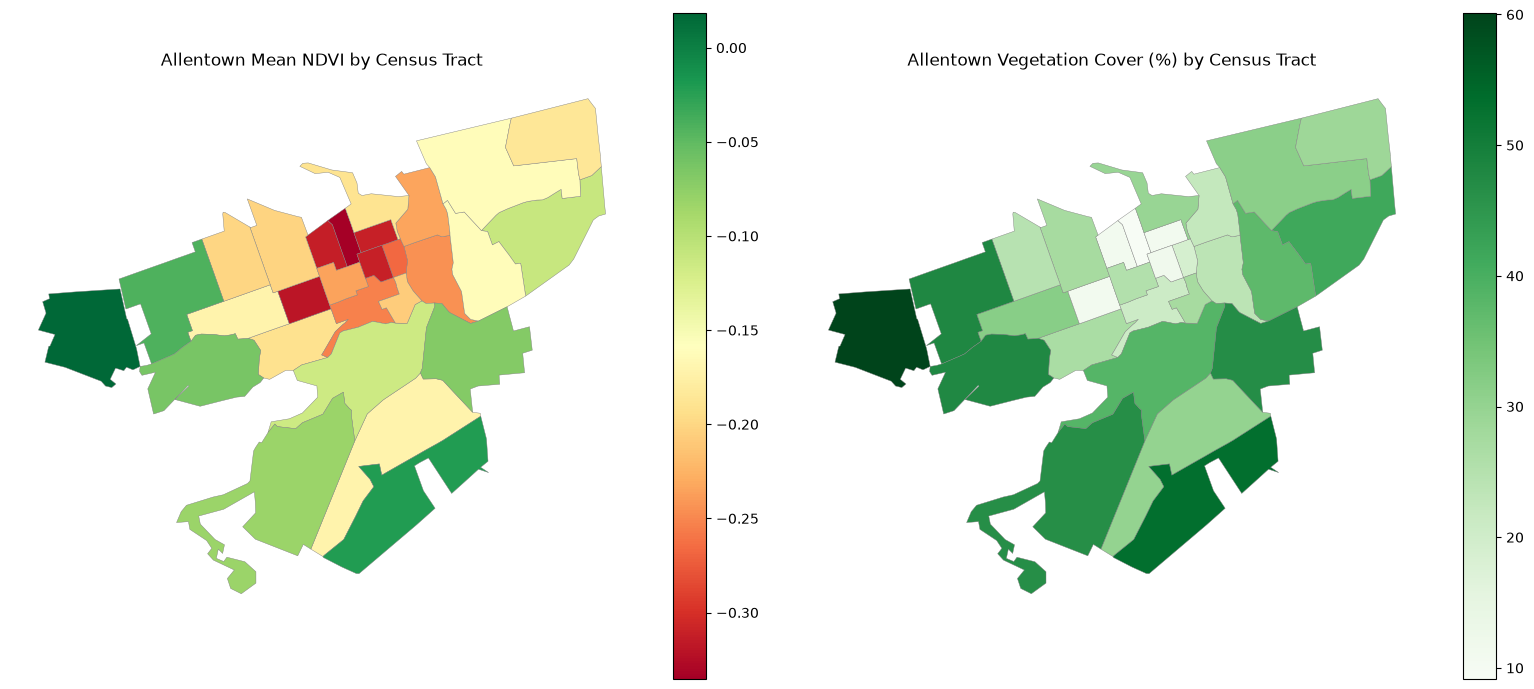

In [46]:
## Census-tract NDVI and vegetation-cover statistics

import fiona
from rasterio.mask import mask

inraster = data_folder / "allentown_naip_clipped.tif"
input_zone_polygon = data_folder / "Allentown_census_tracts_reproj.shp"
output_shp_res = output_folder / "allentown_tract_ndvi_vegetation.shp"

with rasterio.open(inraster) as naip_dataset:
    with fiona.open(input_zone_polygon) as lyr:
        schema = lyr.schema.copy()
        schema["properties"]["mean_ndvi"] = "float:24.8"
        schema["properties"]["veg_pct"] = "float:24.8"

        with fiona.open(output_shp_res, "w", driver="ESRI Shapefile",
                        crs=lyr.crs, schema=schema) as output:
            for feat in lyr:
                props = dict(feat["properties"])
                geom = feat["geometry"]
                out_image, _ = mask(naip_dataset, [geom], nodata=0, crop=True)

                # NAIP: band 1=Red and band 4=Near-Infrared
                red = out_image[0].astype("float32")
                nir = out_image[3].astype("float32")
                valid = (red != 0) | (nir != 0)
                denominator = nir + red

                if np.count_nonzero(valid) == 0:
                    props["mean_ndvi"] = None
                    props["veg_pct"] = None
                else:
                    ndvi = np.zeros(red.shape, dtype="float32")
                    np.divide(nir - red, denominator, out=ndvi,
                              where=valid & (denominator != 0))
                    props["mean_ndvi"] = float(ndvi[valid].mean())
                    props["veg_pct"] = float(100 * np.count_nonzero((ndvi > 0) & valid) /
                                             np.count_nonzero(valid))

                output.write({"properties": props, "geometry": geom})

tract_results = gpd.read_file(output_shp_res)
print("Census-tract results saved to:", output_shp_res)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
tract_results.plot(column="mean_ndvi", cmap="RdYlGn", legend=True,
                  ax=axes[0], edgecolor="gray", linewidth=0.3)
axes[0].set_title("Allentown Mean NDVI by Census Tract")
axes[0].set_axis_off()
tract_results.plot(column="veg_pct", cmap="Greens", legend=True,
                  ax=axes[1], edgecolor="gray", linewidth=0.3)
axes[1].set_title("Allentown Vegetation Cover (%) by Census Tract")
axes[1].set_axis_off()
plt.tight_layout()
plt.show()